# Weekly fee-revenue variability

This notebook builds a merchant volatility feature and covariance estimates, then measures risk for the **unchanged revenue-only top 100**. It does not optimize a new portfolio or introduce fraud/customer-concentration scores.

**Expected return:** historical mean monthly gross fees, including audited zero-sales months. **Risk:** variability of weekly gross fees over the most recent 26 complete Monday-Sunday weeks. These are explicitly different reporting intervals; weekly standard deviation is not monthly/annual total uncertainty or settlement cash-flow risk.

Inputs are the existing audited daily/monthly panels and original merchant metadata. The supplied history is synthetic; take rates and categories are assumed stable and historically available. Gross fees exclude losses and costs.

## Definitions and chronology

For merchant $i$ and week $w$, $F_{i,w}=S_{i,w}\,t_i/100$. The merchant feature is $\operatorname{sd}(F_{i,w})$ with **ddof=1**, across 26 complete weeks available at selection. Genuine zero-sales weeks count; missing source coverage is an error.

For selected merchants $P$, sample portfolio volatility is $\operatorname{sd}(\sum_{i\in P}F_{i,w})=\sqrt{z^\top S z}$. Adding fees before measuring volatility captures covariance. Averaging merchant standard deviations does not.

The separate regularized estimate uses $\widehat\Sigma=(1-\alpha)S+\alpha\operatorname{diag}(S)$. Ledoit-Wolf estimates alpha from standardized, nonconstant eligible histories; individual variances are preserved. A lower regularized estimate is **not an achieved reduction in risk**.

Evaluate the eight existing November 2021-June 2022 cutoffs and build current features at 30 September 2022. The latter uses 28 March-25 September. Future checks hold the original selection fixed and include only whole weeks inside the next three calendar months. Incomplete future periods remain unscored. All evaluations are retrospective and overlapping; there is no untouched holdout.

## Reproduce

From the repository root, use the existing `code/requirements-forecast.txt` environment. No GPU, foundation-model weights, network service or API key is needed. Required audited inputs must already exist; changed fingerprints or incomplete calendars stop the run.

```text
python code/cash_flow_variability.py
python -m pytest -p no:capture code/tests/test_cash_flow_variability.py -q
```

The following cell also runs the complete workflow. It writes only this experiment's ignored output directory and leaves earlier experiments unchanged.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import StrMethodFormatter
from IPython.display import display, Markdown

here = Path.cwd()
ROOT = next(p for p in [here, *here.parents] if (p / "code/cash_flow_variability.py").exists())
sys.path.insert(0, str(ROOT / "code"))
import cash_flow_variability as cf

features, diagnostics = cf.run()

Building weekly risk measures at 2021-11-30


Building weekly risk measures at 2021-12-31


Building weekly risk measures at 2022-01-31


Building weekly risk measures at 2022-02-28


Building weekly risk measures at 2022-03-31


Building weekly risk measures at 2022-04-30


Building weekly risk measures at 2022-05-31


Building weekly risk measures at 2022-06-30


Building weekly risk measures at 2022-09-30


     as_of  selected_merchants  expected_monthly_fees  history_weeks  history_weekly_mean  history_weekly_sd  regularized_weekly_sd  shrinkage_alpha  future_weeks  future_weekly_mean  future_weekly_sd  future_full_week_fees                        future_status  eligible_merchants
2021-11-30                 100            1598829.266             26           388905.862          79603.474              42800.082            0.722            12          363981.657         97613.086            4367779.890                             observed                3895
2021-12-31                 100            1663884.401             26           419939.523          95607.542              70858.442            0.457            12          319634.801         29488.543            3835617.615                             observed                3893
2022-01-31                 100            1631353.551             26           413071.686         103224.849              79852.388            0.407         

## Merchant feature output

There is one row per merchant and cutoff. `weekly_volatility` is a merchant-level feature in AUD per week; `weekly_variance` is in squared AUD. The eligibility columns remain alongside the feature: zero volatility from inactivity is not evidence of a safe merchant. Only eligible merchants enter the baseline selection.

,merchant_abn,name,eligible,eligibility_reason,expected_monthly_fees,weekly_mean_fees,weekly_volatility,active_weeks,n_weeks,window_start,window_end
35362,79827781481,Amet Risus Inc.,True,eligible,33161.999483,8072.530823,1421.604478,26,26,2022-03-28,2022-09-25
33974,48534649627,Dignissim Maecenas Foundation,True,eligible,31088.087839,7769.525225,636.875230,26,26,2022-03-28,2022-09-25
33242,32361057556,Orci In Consequat Corporation,True,eligible,31053.347465,7713.784583,614.037104,26,26,2022-03-28,2022-09-25
35651,86578477987,Leo In Consulting,True,eligible,30586.118562,7614.727488,618.667231,26,26,2022-03-28,2022-09-25
33537,38700038932,Etiam Bibendum Industries,True,eligible,30106.623490,7457.109009,925.260311,26,26,2022-03-28,2022-09-25
33845,45629217853,Lacus Consulting,True,eligible,29233.139008,7290.785917,536.018881,26,26,2022-03-28,2022-09-25
36089,96680767841,Ornare Limited,True,eligible,28873.185259,7218.007129,585.406943,26,26,2022-03-28,2022-09-25
32727,21439773999,Mauris Non Institute,True,eligible,28634.957886,7096.222030,522.926733,26,26,2022-03-28,2022-09-25
34594,63123845164,Odio Phasellus Institute,True,eligible,28213.797077,6957.783965,921.314849,26,26,2022-03-28,2022-09-25
34654,64403598239,Lobortis Ultrices Company,True,eligible,27879.515277,6893.521515,591.574919,26,26,2022-03-28,2022-09-25


,measure,count
0,All merchants,4026
1,Eligible,3897
2,Zero observed volatility,29


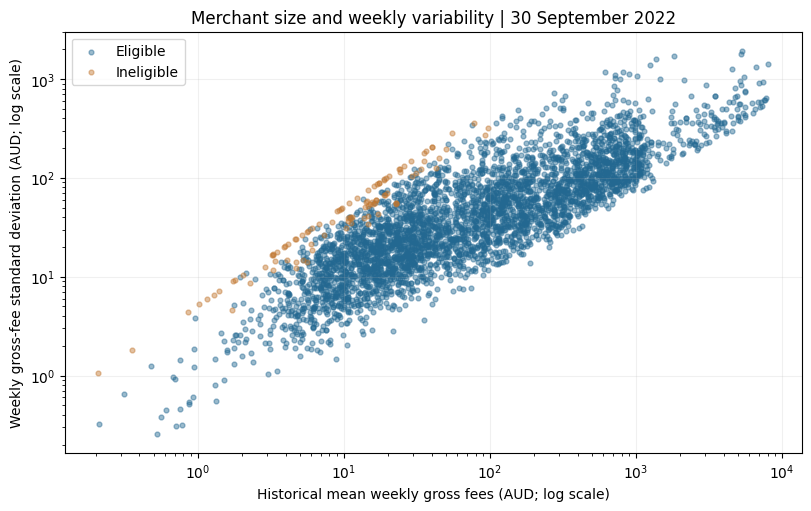

Log plot excludes 29 merchants with zero mean or zero standard deviation.


In [2]:
latest = features.loc[features.as_of.eq(cf.CUTOFFS[-1])].copy()
columns = ["merchant_abn", "name", "eligible", "eligibility_reason", "expected_monthly_fees",
           "weekly_mean_fees", "weekly_volatility", "active_weeks", "n_weeks", "window_start", "window_end"]
display(latest.sort_values("expected_monthly_fees", ascending=False)[columns].head(15))
display(pd.DataFrame({"measure": ["All merchants", "Eligible", "Zero observed volatility"],
                      "count": [len(latest), int(latest.eligible.sum()), int(latest.weekly_volatility.eq(0).sum())]}))

fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
positive = latest.weekly_mean_fees.gt(0) & latest.weekly_volatility.gt(0)
for eligible, label, color in [(True, "Eligible", "#236891"), (False, "Ineligible", "#c17730")]:
    points = latest.loc[positive & latest.eligible.eq(eligible)]
    ax.scatter(points.weekly_mean_fees, points.weekly_volatility, s=12, alpha=.45, label=label, color=color)
ax.set(xscale="log", yscale="log", xlabel="Historical mean weekly gross fees (AUD; log scale)",
       ylabel="Weekly gross-fee standard deviation (AUD; log scale)",
       title="Merchant size and weekly variability | 30 September 2022")
ax.grid(alpha=.18)
ax.legend()
plt.show()
print(f"Log plot excludes {(~positive).sum()} merchants with zero mean or zero standard deviation.")

## Baseline portfolio diagnostics

Sample historical SD is directly observed. Regularized SD is a separate estimate using the same selected merchants. Future SD measures a later, shorter sample of 11-13 complete weeks; it is not a significance test or proof of calibration. Compare these columns without interpreting differences as a benefit from changed merchant selection.

,as_of,eligible_merchants,selected_merchants,expected_monthly_fees,history_weekly_mean,history_weekly_sd,regularized_weekly_sd,shrinkage_alpha,future_weeks,future_weekly_mean,future_weekly_sd,future_status
0,2021-11-30,3895,100,1.598829e+06,388905.861569,79603.473770,42800.081680,0.721803,12,363981.657459,97613.085583,observed
1,2021-12-31,3893,100,1.663884e+06,419939.523354,95607.542234,70858.442350,0.457143,12,319634.801221,29488.542910,observed
2,2022-01-31,3900,100,1.631354e+06,413071.685521,103224.849434,79852.388438,0.407116,11,347871.484463,28312.345505,observed
3,2022-02-28,3891,100,1.598974e+06,404817.542068,108741.524805,86304.656413,0.375210,12,380424.195553,23419.318972,observed
4,2022-03-31,3872,100,1.596617e+06,401718.534847,110027.491902,87863.992833,0.367269,12,396886.984404,19142.786257,observed
5,2022-04-30,3868,100,1.597001e+06,399124.451011,110802.409005,88536.886192,0.366539,13,412704.370125,13537.490294,observed
6,2022-05-31,3859,100,1.610121e+06,380130.850298,83407.317368,63216.091753,0.431941,12,426106.951245,18810.700232,observed
7,2022-06-30,3864,100,1.619964e+06,359820.615398,45469.514810,27828.733659,0.639430,12,436053.178322,19113.578519,observed
8,2022-09-30,3897,100,1.666400e+06,414775.026746,29216.121623,13167.757759,0.830553,0,NaN,NaN,insufficient_complete_outcome_period


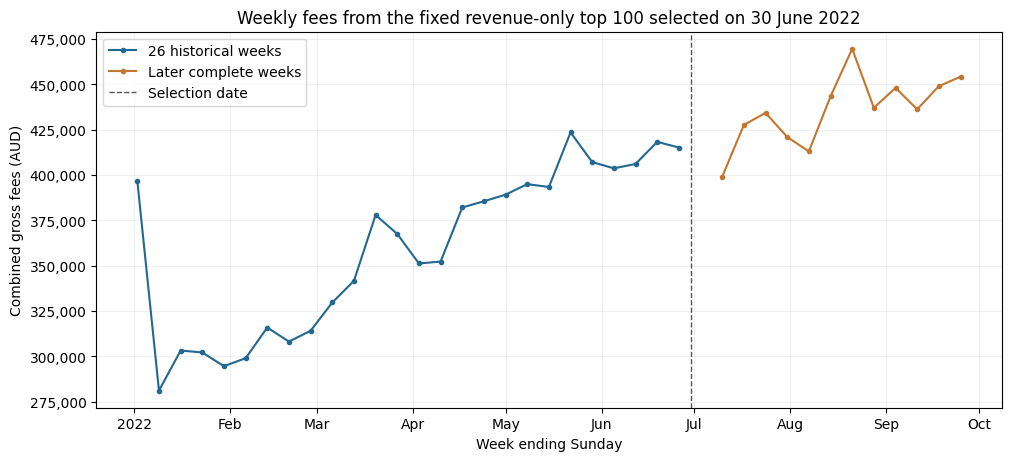

In [3]:
display(diagnostics[["as_of", "eligible_merchants", "selected_merchants", "expected_monthly_fees",
                     "history_weekly_mean", "history_weekly_sd", "regularized_weekly_sd", "shrinkage_alpha",
                     "future_weeks", "future_weekly_mean", "future_weekly_sd", "future_status"]])

weeks = pd.read_parquet(cf.OUT / "portfolio_weekly_fees.parquet")
chosen = weeks.loc[weeks.as_of.eq(pd.Timestamp("2022-06-30"))]
fig, ax = plt.subplots(figsize=(10, 4.5), layout="constrained")
for phase, label, color in [("history", "26 historical weeks", "#236891"), ("future", "Later complete weeks", "#c17730")]:
    line = chosen.loc[chosen.phase.eq(phase)]
    ax.plot(line.week_end, line.gross_fees, marker="o", markersize=3, label=label, color=color)
ax.axvline(pd.Timestamp("2022-06-30"), color="#555555", linestyle="--", linewidth=1, label="Selection date")
locator = mdates.AutoDateLocator()
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.set(title="Weekly fees from the fixed revenue-only top 100 selected on 30 June 2022",
       xlabel="Week ending Sunday", ylabel="Combined gross fees (AUD)")
ax.grid(alpha=.18)
ax.legend()
plt.show()

## Reuse covariance and verify outputs

The covariance representation stores labeled centered observations and sample variances, plus alpha and week dates. It avoids exporting a dense 4,026-by-4,026 matrix. Helpers preserve the requested ABN order, reject duplicate/unknown ABNs, and require an explicit `sample` or `shrunk` estimator.

In [4]:
as_of = cf.CUTOFFS[-1]
model = cf.load_covariance(cf.OUT / "covariance" / as_of.strftime("%Y-%m-%d"))
selected = cf.baseline_selection(latest)
ids = selected.merchant_abn.tolist()
display(cf.covariance_submatrix(model, ids[:5], estimator="sample"))
print("Portfolio sample weekly SD:", round(cf.portfolio_volatility(model, ids, estimator="sample"), 2))
print("Portfolio regularized weekly SD:", round(cf.portfolio_volatility(model, ids, estimator="shrunk"), 2))
display(pd.read_parquet(cf.OUT / "cutoff_checks.parquet"))
display(Markdown((cf.OUT / "findings.md").read_text(encoding="utf-8")))

,79827781481,48534649627,32361057556,86578477987,38700038932
merchant_abn,,,,,
79827781481,2.020959e+06,333376.145794,327167.049008,314740.962059,-138084.712283
48534649627,3.333761e+05,405610.058688,317676.991264,339271.295793,106059.630605
32361057556,3.271670e+05,317676.991264,377041.564769,342873.536099,139230.208195
86578477987,3.147410e+05,339271.295793,342873.536099,382749.143252,222488.857225
38700038932,-1.380847e+05,106059.630605,139230.208195,222488.857225,856106.642767


Portfolio sample weekly SD: 29216.12
Portfolio regularized weekly SD: 13167.76


,as_of,sample_diagonal_and_portfolio_reconciled,covariance_psd,covariance_roundtrip_exact,baseline_reproduced,future_transaction_perturbation
0,2021-11-30,True,True,True,True,True
1,2021-12-31,True,True,True,True,True
2,2022-01-31,True,True,True,True,True
3,2022-02-28,True,True,True,True,True
4,2022-03-31,True,True,True,True,True
5,2022-04-30,True,True,True,True,True
6,2022-05-31,True,True,True,True,True
7,2022-06-30,True,True,True,True,True
8,2022-09-30,True,True,True,False,False


# Weekly fee-revenue variability

Expected return remains the expanding historical mean monthly gross fees. This workflow measures risk for the revenue-only top 100; it does not select a risk-optimized portfolio.

Each merchant's volatility is the sample standard deviation (ddof=1) of its last 26 full Monday-Sunday weekly gross fees. Portfolio sample SD is calculated after summing merchant fees. Covariance therefore captures contemporaneous co-movement. The regularized estimate shrinks correlations, preserving individual variances; a smaller estimate is not an achieved reduction in risk.

Latest cutoff: 2022-09-30; window: 2022-03-28 through 2022-09-25. All 4,026 merchants have features; 3,897 are eligible. 29 have zero measured volatility; inactivity does not imply a safe or eligible merchant.

| Cutoff | Expected monthly fees | Historical weekly SD | Regularized weekly SD | Later weekly SD | Later full weeks |
|---|---:|---:|---:|---:|---:|
| 2021-11-30 | A$1,598,829.27 | A$79,603.47 | A$42,800.08 | A$97,613.09 | 12 |
| 2021-12-31 | A$1,663,884.40 | A$95,607.54 | A$70,858.44 | A$29,488.54 | 12 |
| 2022-01-31 | A$1,631,353.55 | A$103,224.85 | A$79,852.39 | A$28,312.35 | 11 |
| 2022-02-28 | A$1,598,973.98 | A$108,741.52 | A$86,304.66 | A$23,419.32 | 12 |
| 2022-03-31 | A$1,596,617.50 | A$110,027.49 | A$87,863.99 | A$19,142.79 | 12 |
| 2022-04-30 | A$1,597,001.48 | A$110,802.41 | A$88,536.89 | A$13,537.49 | 13 |
| 2022-05-31 | A$1,610,121.16 | A$83,407.32 | A$63,216.09 | A$18,810.70 | 12 |
| 2022-06-30 | A$1,619,964.00 | A$45,469.51 | A$27,828.73 | A$19,113.58 | 12 |
| 2022-09-30 | A$1,666,399.53 | A$29,216.12 | A$13,167.76 | Unavailable | 0 |

Later SD uses only whole weeks inside the following three calendar months, excluding boundary weeks; total fees in these weeks are not a complete three-month revenue total. All selections stay fixed. The September cutoff has no complete future evaluation period in the audited panel.

The 26-week window is a fixed starting choice, not a proven optimum. Regularization is an estimation choice, not evidence of accurate future risk. Trends and calendar effects remain in the histories. Weekly SD is not settlement cash-flow risk, credit loss, a confidence interval, or annual/monthly total uncertainty. Do not scale it by the square root of time without examining serial dependence.

Categories and take rates are assumed stable and historically available. Gross fees exclude fraud, funding and operating costs. Transactions for merchants without metadata remain outside fee-based selection. The data are synthetic and the short overlapping evaluations are retrospective, with no untouched holdout. This report makes no statistical-significance or improved-selection claim.

Reproduce: `python code/cash_flow_variability.py`. Validate: `python -m pytest -p no:capture code/tests/test_cash_flow_variability.py -q`. Use the existing requirements-forecast.txt environment; no GPU or network service is needed.

Covariance factors are stored per cutoff with ABN labels and JSON settings. Use load_covariance, covariance_submatrix and portfolio_volatility with estimator='sample' or 'shrunk'. Sample SD reproduces the observed historical feature; shrunk SD is separately labelled. Artifacts are uncompressed Parquet, with CSV views of feature and summary tables.


## Limits and next-stage boundary

The 26-week lookback and shrinkage method are fixed starting specifications, not tuned winners. Large merchants often have larger dollar volatility; a later optimizer must compare risk while retaining an explicit level of expected revenue. Trends and calendar effects are retained. Zero empirical variance is not proof of zero future risk.

Outputs are under `tables/analysis/cash_flow_variability/`: weekly panel, merchant features, baseline selections, covariance factors/settings, historical and future portfolio diagnostics, provenance, freeze record and acceptance checks. Parquet is uncompressed, with CSV views for the main feature and summary tables.

No fraud loss assumptions, customer-concentration penalties, optimized selections or claims of risk reduction are introduced here.